In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight
from sklearn.tree import DecisionTreeClassifier

In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../../../Edge-IIoTset_ML-112.csv')

In [4]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [5]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [6]:
# Load precomputed selected features
feature_list_path = "../selected_features_15class_mi.pkl"
with open(feature_list_path, "rb") as f:
    selected_features = pickle.load(f)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.2, random_state=42)

In [8]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (121796, 40)
X_test shape: (30449, 40)


In [9]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
def decision_tree_model_15class():
    model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        ccp_alpha=0.0,
        random_state=42
    )
    return model

model = decision_tree_model_15class()

In [11]:
# Train the model
model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [12]:
# Predict on the test set
y_pred = model.predict(X_test)

In [13]:
y_pred_classes = y_pred

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:")
print(classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))], zero_division=0))


Accuracy: 0.9563204046109889
Classification Report:
                       precision    recall  f1-score   support

               Normal       1.00      1.00      1.00      4837
                 MITM       1.00      1.00      1.00        80
            Uploading       0.90      0.90      0.90      1961
           Ransomware       0.98      0.98      0.98      2031
        SQL_injection       0.85      0.87      0.86      2076
            DDoS_HTTP       0.91      0.91      0.91      2191
             DDoS_TCP       1.00      1.00      1.00      2028
             Password       0.85      0.84      0.84      1998
        Port_Scanning       1.00      1.00      1.00      1793
Vulnerability_scanner       0.98      0.98      0.98      2034
             Backdoor       0.98      0.98      0.98      2013
                  XSS       0.90      0.91      0.90      1855
       Fingerprinting       0.96      0.95      0.95       177
             DDoS_UDP       1.00      1.00      1.00      2813
  

In [14]:
# Get detailed report as a dictionary
report_dict = classification_report(
    y_test,
    y_pred_classes,
    target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))],
    output_dict=True
)

# Convert to DataFrame and format with more floats
report_df = pd.DataFrame(report_dict).T  # transpose for better layout
report_df = report_df.round(4)  # round to 4 decimal places

print(report_df)

                       precision  recall  f1-score     support
Normal                    1.0000  1.0000    1.0000   4837.0000
MITM                      1.0000  1.0000    1.0000     80.0000
Uploading                 0.8980  0.8975    0.8977   1961.0000
Ransomware                0.9769  0.9769    0.9769   2031.0000
SQL_injection             0.8526  0.8695    0.8610   2076.0000
DDoS_HTTP                 0.9142  0.9092    0.9117   2191.0000
DDoS_TCP                  1.0000  1.0000    1.0000   2028.0000
Password                  0.8534  0.8363    0.8448   1998.0000
Port_Scanning             0.9961  0.9961    0.9961   1793.0000
Vulnerability_scanner     0.9778  0.9759    0.9769   2034.0000
Backdoor                  0.9757  0.9767    0.9762   2013.0000
XSS                       0.8990  0.9067    0.9028   1855.0000
Fingerprinting            0.9600  0.9492    0.9545    177.0000
DDoS_UDP                  1.0000  1.0000    1.0000   2813.0000
DDoS_ICMP                 1.0000  1.0000    1.0000   25

In [15]:
# Get predicted probabilities: shape (n_samples, n_classes)
y_pred_proba = model.predict_proba(X_test)

# Binarize the true labels: shape (n_samples, n_classes)
y_test_bin = label_binarize(y_test, classes=list(attacks.values()))

# Compute AUC scores
auc_macro = roc_auc_score(y_test_bin, y_pred_proba, average='macro', multi_class='ovr')
auc_weighted = roc_auc_score(y_test_bin, y_pred_proba, average='weighted', multi_class='ovr')

print(f"AUC (macro-averaged OvR): {auc_macro:.4f}")
print(f"AUC (weighted-averaged OvR): {auc_weighted:.4f}")

AUC (macro-averaged OvR): 0.9750
AUC (weighted-averaged OvR): 0.9767


In [16]:
n_samples = min(100, len(X_test))
total_time = 0.0

for i in range(n_samples):
    sample = X_test[i].reshape(1, -1)  # Shape: (1, features)
    start_time = time.time()
    _ = model.predict_proba(sample)  # or model.predict(sample)
    total_time += time.time() - start_time

avg_inference_time = total_time / n_samples
print(f"Average inference time per sample: {avg_inference_time:.6f} seconds")

Average inference time per sample: 0.000575 seconds


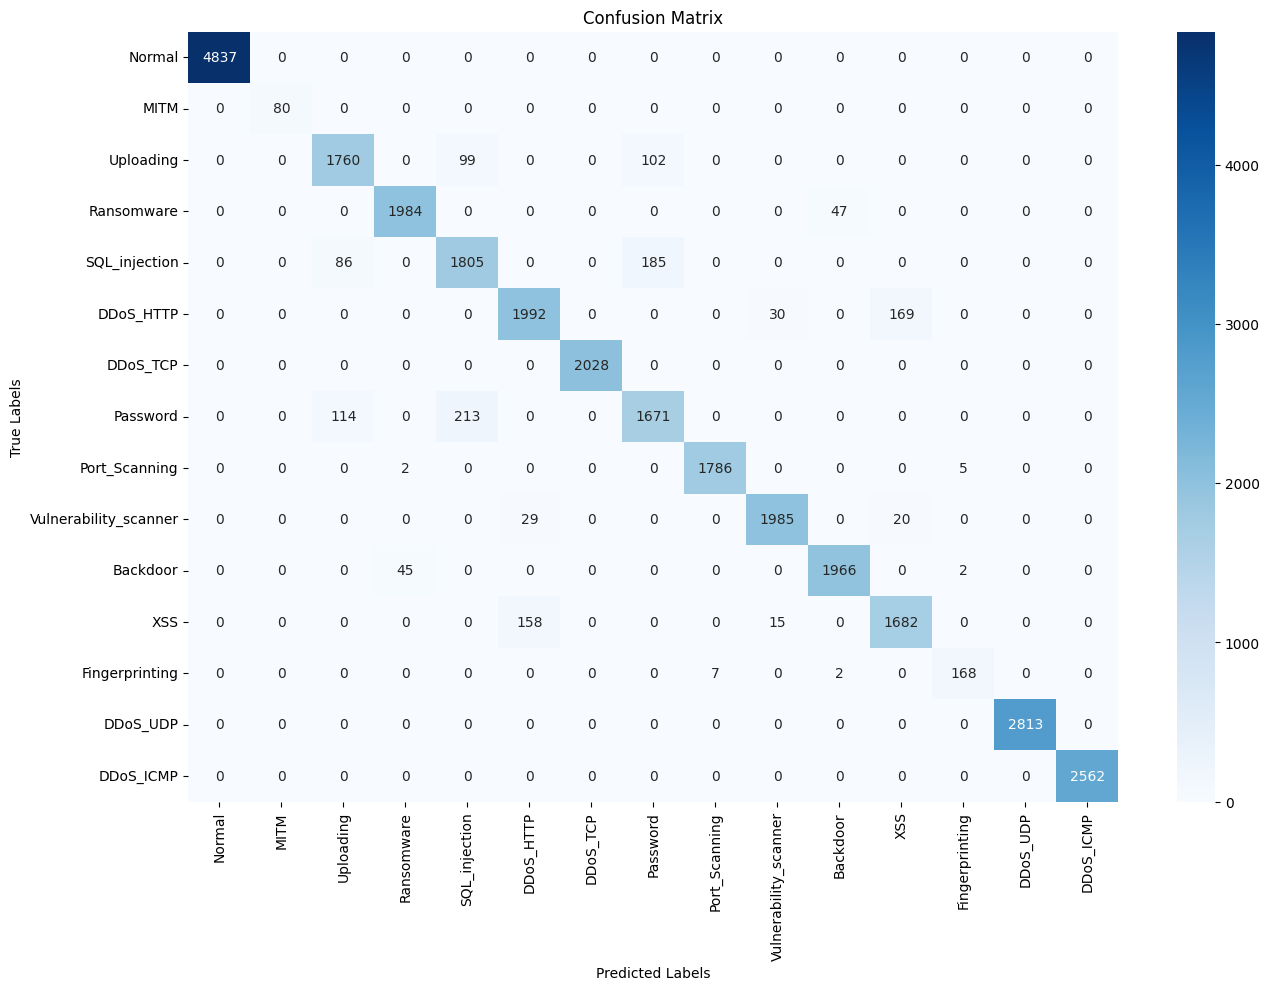

In [17]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

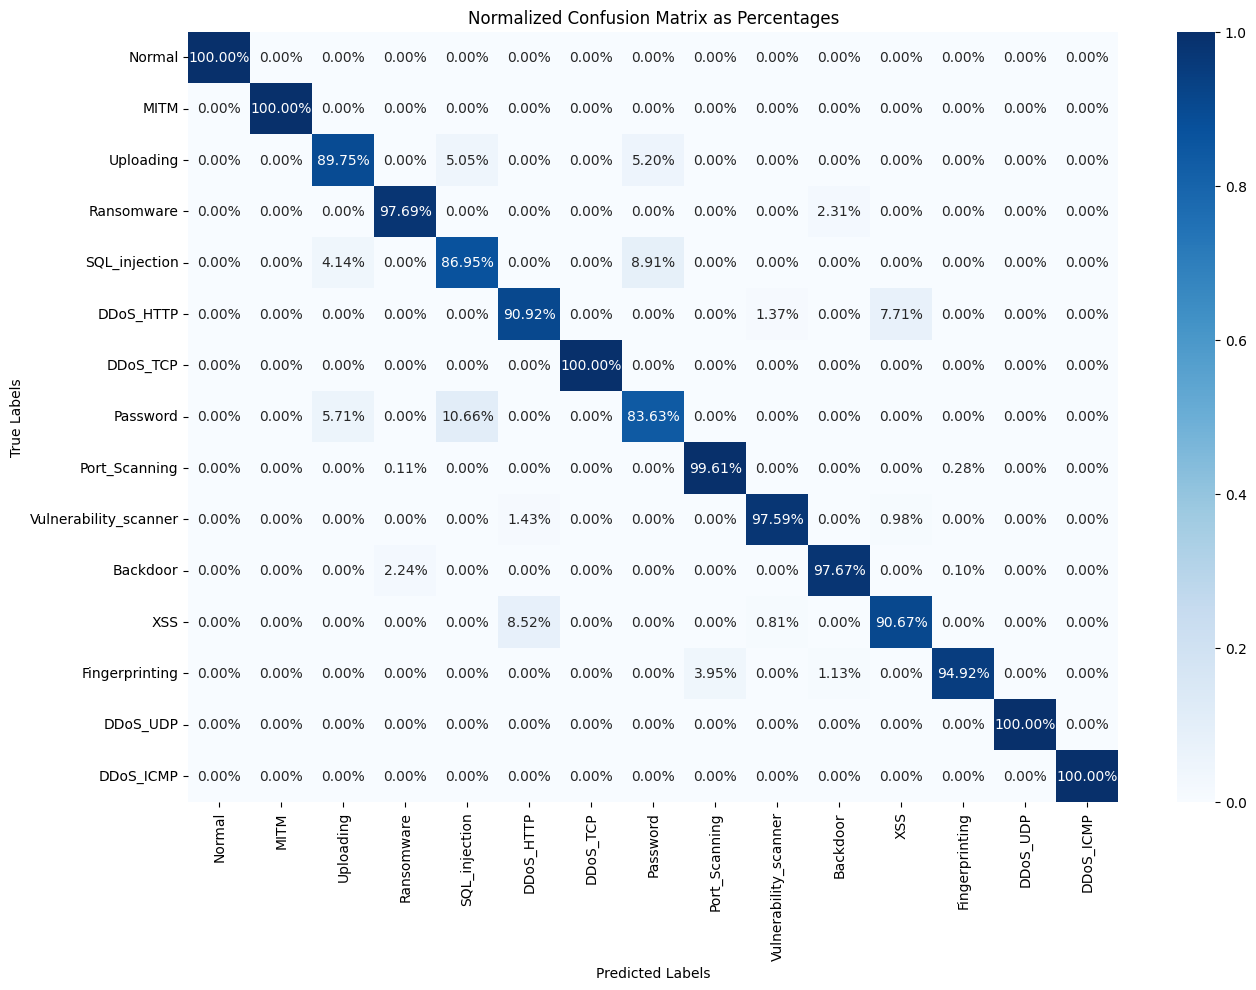

In [18]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()